**Practical-12: Metropolis Algorithm and Deterministic Model**

**Part A: Implementation of Metropolis Algorithm**

**Aim**:

To implement the Metropolis algorithm to generate samples from a probability distribution using the Markov Chain Monte Carlo (MCMC) technique.

**Theory**:

The Metropolis algorithm is an MCMC method used to generate random samples from a probability distribution.

It works by:

Selecting an initial value.

Proposing a new random value.

Calculating the acceptance probability.

Accepting or rejecting the proposed value.

Repeating the process to generate samples.

The algorithm is useful when direct sampling from a probability distribution is difficult.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

**Implement the Metropolis algorithm**

In [2]:
def metropolis_algorithm(n_samples, initial_value, proposal_std):

    samples = []
    current = initial_value
    accepted = 0

    for i in range(n_samples):

        # Generate a proposed value
        proposed = np.random.normal(current, proposal_std)

        # Calculate acceptance probability
        acceptance_ratio = min(
            1,
            np.exp(-0.5 * (proposed**2 - current**2))
        )

        # Accept or reject the proposed value
        if np.random.rand() < acceptance_ratio:
            current = proposed
            accepted += 1

        samples.append(current)

    acceptance_rate = accepted / n_samples

    return np.array(samples), acceptance_rate

**Generate samples**

In [3]:
samples, acceptance_rate = metropolis_algorithm(
    n_samples=10000,
    initial_value=0,
    proposal_std=1
)

print("First 10 samples:", samples[:10])
print("Acceptance Rate:", acceptance_rate)

First 10 samples: [ 0.49671415  0.35844985  0.12429648 -0.10984048  1.46937234  1.46937234
  0.99989795  1.54245799  1.78442026 -0.12885998]
Acceptance Rate: 0.7116


**Visualize the results**

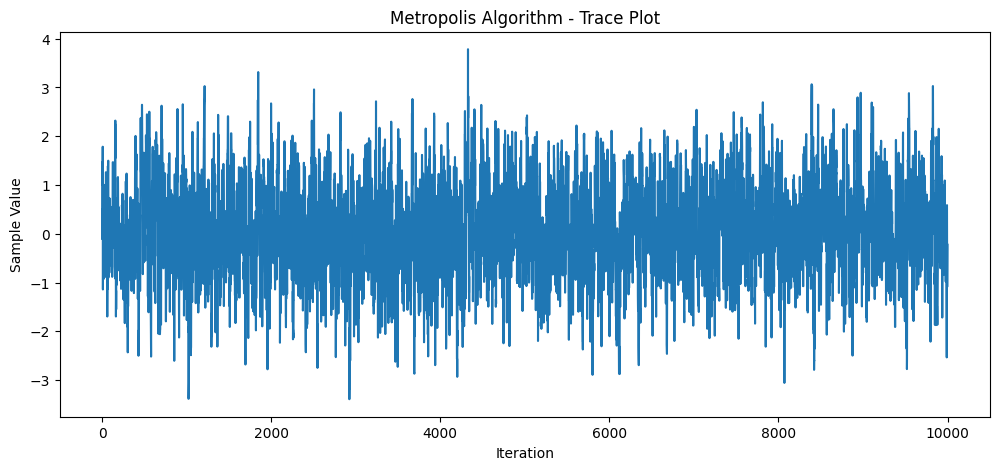

In [4]:
#Graph 1 – Trace Plot
plt.figure(figsize=(12, 5))
plt.plot(samples)
plt.title("Metropolis Algorithm - Trace Plot")
plt.xlabel("Iteration")
plt.ylabel("Sample Value")
plt.show()

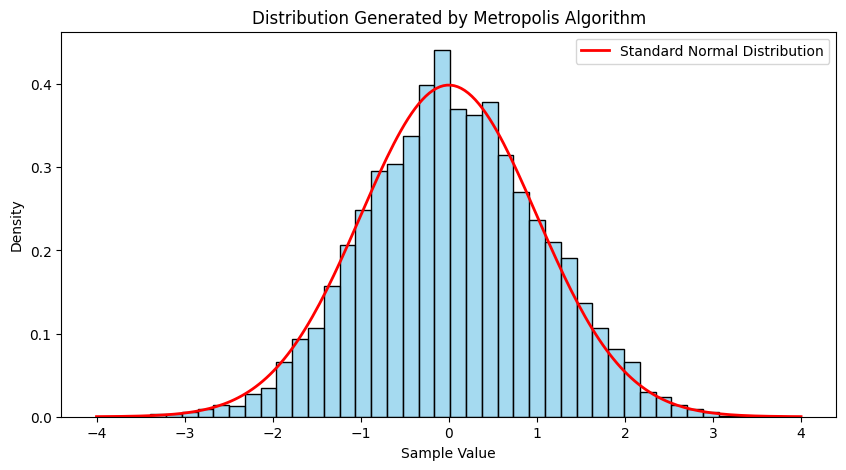

In [5]:
#Graph 2 – Distribution of Samples
plt.figure(figsize=(10, 5))

sns.histplot(samples, bins=40, stat="density",
             color="skyblue", edgecolor="black")

x = np.linspace(-4, 4, 200)
y = (1 / np.sqrt(2 * np.pi)) * np.exp(-x**2 / 2)

plt.plot(x, y, color="red", linewidth=2,
         label="Standard Normal Distribution")

plt.title("Distribution Generated by Metropolis Algorithm")
plt.xlabel("Sample Value")
plt.ylabel("Density")
plt.legend()
plt.show()

**Calculate basic statistics**

In [6]:
print("Mean:", np.mean(samples))
print("Variance:", np.var(samples))
print("Standard Deviation:", np.std(samples))
print("Acceptance Rate:", acceptance_rate)

Mean: 0.05488577403564897
Variance: 1.00019240608585
Standard Deviation: 1.0000961984158574
Acceptance Rate: 0.7116


**Result**:

The Metropolis algorithm was successfully implemented using Python. Samples were generated from a standard normal distribution using the MCMC technique. The generated distribution was compared with the theoretical normal distribution using a histogram.

The algorithm demonstrates how random samples can be generated using acceptance and rejection of proposed values.

**PART B: DETERMINISTIC MODEL**

**Aim**:

To implement a deterministic population growth model using Python and visualize the change in population over time.

**Theory**:

A deterministic model is a mathematical model in which the output is completely determined by the input values and initial conditions.

It does not involve random numbers or uncertainty.

In this practical, we use a population growth model in which the population increases at a fixed growth rate over time.

The model assumes that the growth rate remains constant and that there are no unexpected changes in the environment.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

**Define the deterministic model**

In [8]:
# Initial population
N0 = 100

# Growth rate (5%)
r = 0.05

# Time period
t = np.arange(0, 51, 1)

# Exponential population growth model
population = N0 * np.exp(r * t)

# Display population values
data = pd.DataFrame({
    "Time": t,
    "Population": population
})

print(data.head(10))

   Time  Population
0     0  100.000000
1     1  105.127110
2     2  110.517092
3     3  116.183424
4     4  122.140276
5     5  128.402542
6     6  134.985881
7     7  141.906755
8     8  149.182470
9     9  156.831219


**Visualize the population growth**

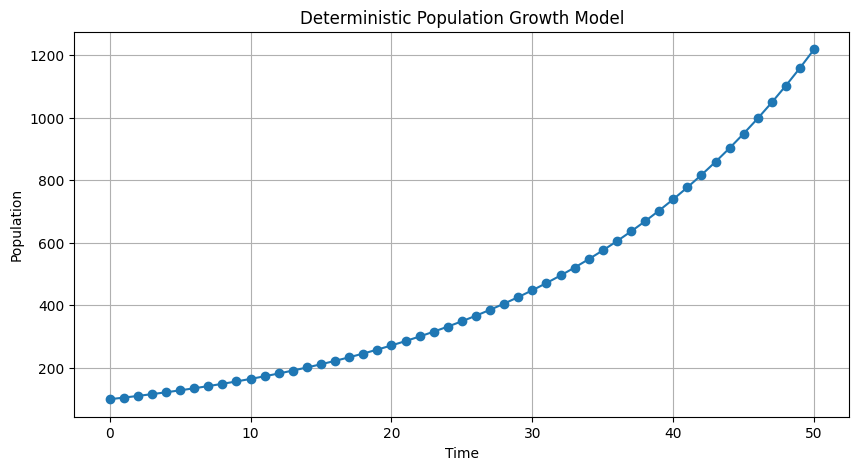

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(t, population, marker='o')

plt.title("Deterministic Population Growth Model")
plt.xlabel("Time")
plt.ylabel("Population")
plt.grid(True)

plt.show()

**Calculate population statistics**

In [10]:
print("Initial Population:", N0)
print("Growth Rate:", r * 100, "%")
print("Final Population:", round(population[-1], 2))
print("Maximum Population:", round(np.max(population), 2))

Initial Population: 100
Growth Rate: 5.0 %
Final Population: 1218.25
Maximum Population: 1218.25


**Compare initial and final population**

In [11]:
print("Population at different time intervals:")

for year in [0, 10, 20, 30, 40, 50]:
    print(f"Year {year}: {population[year]:.2f}")

Population at different time intervals:
Year 0: 100.00
Year 10: 164.87
Year 20: 271.83
Year 30: 448.17
Year 40: 738.91
Year 50: 1218.25


**Result**:

The deterministic population growth model was successfully implemented using Python.

The exponential growth equation was used to calculate population changes over time. The graph shows that the population increases continuously at a constant growth rate.

This practical demonstrates that a deterministic model produces predictable results when the initial conditions and parameters are fixed.